# Práctica 1 · Clasificación de frutas con CNN (PyTorch)
**AA II · 2026–27**. En primer lugar, importamos las librerías necesarias y configuramos las rutas de Google Drive, donde guardaremos los datos, los modelos y los resultados. También fijamos una semilla para que los experimentos sean lo más reproducibles posible.

## 1. Entorno, reproducibilidad y Drive

In [1]:
from google.colab import drive
import os
import zipfile

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/AA2_Practica1_Fruits'
ZIP_PATH = os.path.join(PROJECT_DIR, 'Fruit_dataset.zip')
DATA_DIR = '/content/Fruit_dataset'

print("¿Existe el ZIP?", os.path.isfile(ZIP_PATH))

if not os.path.isfile(ZIP_PATH):
    raise FileNotFoundError(f"No se encuentra: {ZIP_PATH}")

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Dataset extraído correctamente")
print("Contenido:", os.listdir(DATA_DIR))

Mounted at /content/drive
¿Existe el ZIP? True
Dataset extraído correctamente
Contenido: ['__MACOSX', 'Fruit_dataset']


In [2]:
from pathlib import Path
import os, zipfile, hashlib, random, shutil, copy, json, time
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, f1_score
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', device)

ROOT = Path(PROJECT_DIR)
ZIP = Path(ZIP_PATH)

DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'
MODELS = ROOT / 'models'

for p in [DATA, RESULTS, FIGURES, MODELS]:
    p.mkdir(parents=True, exist_ok=True)

assert ZIP.exists(), f'No se encuentra {ZIP}'

print('Proyecto:', ROOT)
print('Dataset extraído en:', DATA_DIR)

Dispositivo: cuda
Proyecto: /content/drive/MyDrive/AA2_Practica1_Fruits
Dataset extraído en: /content/Fruit_dataset


## 2. Auditoría del ZIP y separación sin fugas
Para esta práctica hemos elegido un dataset de frutas y verduras con diez categorías. Antes de entrenar, revisamos las imágenes para detectar duplicados y evitar que aparezcan los mismos archivos en distintos conjuntos.

Una vez eliminados los duplicados, dividimos las 7.999 imágenes en entrenamiento, validación y test, manteniendo la proporción de las clases. Así podemos entrenar el modelo, comparar configuraciones y comprobar finalmente su rendimiento con imágenes reservadas para la prueba.

In [3]:
from pathlib import Path
from collections import defaultdict, Counter
import hashlib
import pandas as pd

BASE = Path(DATA_DIR)
EXTENSIONS = {'.jpg', '.jpeg', '.png'}

by_split = defaultdict(list)

for archivo in BASE.rglob('*'):
    if not archivo.is_file():
        continue

    if archivo.suffix.lower() not in EXTENSIONS:
        continue

    if '__MACOSX' in archivo.parts or archivo.name.startswith('._'):
        continue

    for split in ('Training', 'Validation', 'Test'):
        if split in archivo.parts:
            i = archivo.parts.index(split)

            if len(archivo.parts) == i + 3:
                categoria = archivo.parts[i + 1]

                with open(archivo, 'rb') as f:
                    digest = hashlib.sha256(f.read()).hexdigest()

                by_split[split].append({
                    'categoria': categoria,
                    'archivo': str(archivo),
                    'hash': digest
                })

            break

print("=== DISTRIBUCIÓN DEL DATASET ===")

for split in ('Training', 'Validation', 'Test'):
    registros = by_split[split]

    print(f"\n{split}")
    print("Total imágenes:", len(registros))
    print("Imágenes únicas:", len(set(r['hash'] for r in registros)))

    categorias = Counter(r['categoria'] for r in registros)

    for categoria, cantidad in sorted(categorias.items()):
        print(f"  {categoria}: {cantidad}")

print("\n=== COMPROBACIÓN DE DUPLICADOS ===")

for a, b in [
    ('Training', 'Validation'),
    ('Training', 'Test'),
    ('Validation', 'Test')
]:
    hashes_a = {r['hash'] for r in by_split[a]}
    hashes_b = {r['hash'] for r in by_split[b]}

    duplicados = hashes_a.intersection(hashes_b)

    print(f"{a} / {b}: {len(duplicados)} duplicados")

print("\n=== RESUMEN ===")

total = sum(len(by_split[s]) for s in ('Training', 'Validation', 'Test'))

print("Total de imágenes:", total)
print("Total de imágenes únicas:", len(set(
    r['hash']
    for registros in by_split.values()
    for r in registros
)))

=== DISTRIBUCIÓN DEL DATASET ===

Training
Total imágenes: 2625
Imágenes únicas: 2625
  Apple: 221
  Avocado: 172
  Banana: 271
  Blackberry: 150
  Cucumber: 618
  Orange: 318
  Pear: 199
  Pepper: 264
  Strawberry: 188
  Tomato: 224

Validation
Total imágenes: 2371
Imágenes únicas: 2371
  Apple: 234
  Avocado: 231
  Banana: 247
  Blackberry: 150
  Cucumber: 236
  Orange: 236
  Pear: 257
  Pepper: 256
  Strawberry: 227
  Tomato: 297

Test
Total imágenes: 3233
Imágenes únicas: 3233
  Apple: 634
  Avocado: 360
  Banana: 157
  Blackberry: 149
  Cucumber: 472
  Orange: 239
  Pear: 399
  Pepper: 399
  Strawberry: 258
  Tomato: 166

=== COMPROBACIÓN DE DUPLICADOS ===
Training / Validation: 66 duplicados
Training / Test: 164 duplicados
Validation / Test: 0 duplicados

=== RESUMEN ===
Total de imágenes: 8229
Total de imágenes únicas: 7999


In [4]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd
import shutil
import hashlib

registros = {}

for split in ('Training', 'Validation', 'Test'):
    for r in by_split[split]:
        digest = r['hash']
        categoria = r['categoria']

        if digest in registros:
            if registros[digest]['categoria'] != categoria:
                raise ValueError(
                    f"Imagen con etiquetas contradictorias: {digest}"
                )
        else:
            registros[digest] = {
                'categoria': categoria,
                'archivo': r['archivo'],
                'hash': digest
            }

df = pd.DataFrame(registros.values())

print("Imágenes únicas:", len(df))
print("Categorías:", sorted(df['categoria'].unique()))

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['categoria'],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=1/3,
    stratify=temp_df['categoria'],
    random_state=SEED
)

DATA = ROOT / 'data'

for split, subset in [
    ('train', train_df),
    ('val', val_df),
    ('test', test_df)
]:
    for _, row in subset.iterrows():

        origen = Path(row['archivo'])

        destino = (
            DATA /
            split /
            row['categoria'] /
            (row['hash'] + origen.suffix.lower())
        )

        destino.parent.mkdir(parents=True, exist_ok=True)

        if not destino.exists():
            shutil.copy2(origen, destino)

print("\n=== NUEVA DISTRIBUCIÓN ===")

for nombre, subset in [
    ('Training', train_df),
    ('Validation', val_df),
    ('Test', test_df)
]:
    print(f"{nombre}: {len(subset)} imágenes")

print("\n=== VERIFICACIÓN DE DUPLICADOS ===")

for a, b in [
    (train_df, val_df),
    (train_df, test_df),
    (val_df, test_df)
]:
    duplicados = set(a['hash']) & set(b['hash'])
    print("Duplicados:", len(duplicados))

manifest_df = pd.concat([
    train_df.assign(split='train'),
    val_df.assign(split='val'),
    test_df.assign(split='test')
], ignore_index=True)

manifest_df.to_csv(
    RESULTS / 'dataset_manifest.csv',
    index=False
)

print("\nDataset preparado correctamente")

Imágenes únicas: 7999
Categorías: ['Apple', 'Avocado', 'Banana', 'Blackberry', 'Cucumber', 'Orange', 'Pear', 'Pepper', 'Strawberry', 'Tomato']

=== NUEVA DISTRIBUCIÓN ===
Training: 5599 imágenes
Validation: 1600 imágenes
Test: 800 imágenes

=== VERIFICACIÓN DE DUPLICADOS ===
Duplicados: 0
Duplicados: 0
Duplicados: 0

Dataset preparado correctamente






## 3. Transformaciones y DataLoaders

En este apartado preparamos los DataLoaders para cargar las imágenes por lotes durante el entrenamiento y la evaluación. También aplicamos las transformaciones necesarias y dejamos la opción de utilizar Data Augmentation para probar si mejora el aprendizaje del modelo.

---



Clases: ['Apple', 'Avocado', 'Banana', 'Blackberry', 'Cucumber', 'Orange', 'Pear', 'Pepper', 'Strawberry', 'Tomato']
Training: 7301
Validation: 2890
Test: 1509


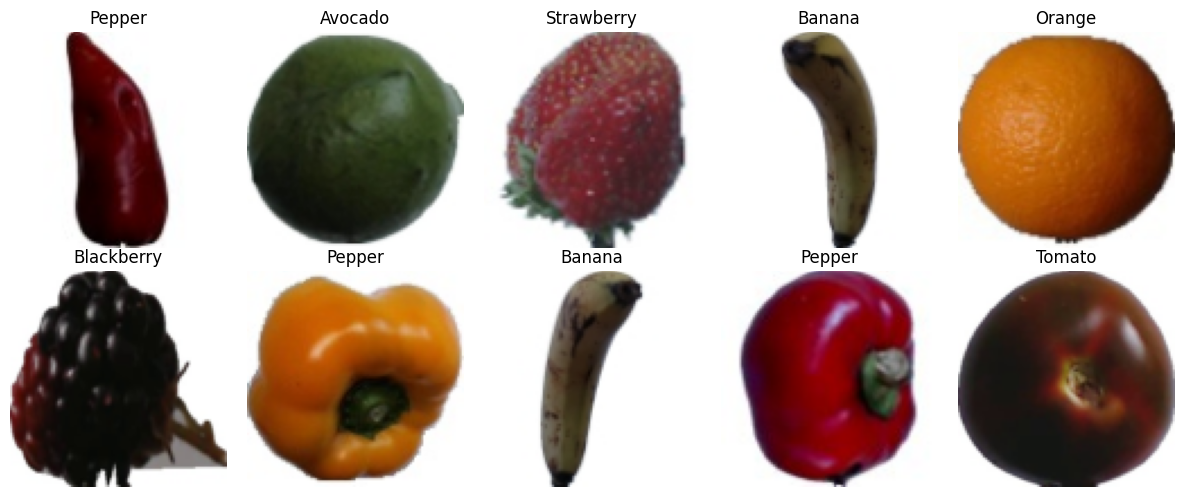

In [5]:
SIZE = 96
BATCH_DEFAULT = 32

base_transform = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])

aug_transform = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(12),
    transforms.ColorJitter(brightness=0.12, contrast=0.12),
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])

def make_loaders(batch_size=32, augmentation=False):

    train_ds = ImageFolder(
        DATA / 'train',
        transform=aug_transform if augmentation else base_transform
    )

    val_ds = ImageFolder(
        DATA / 'val',
        transform=base_transform
    )

    test_ds = ImageFolder(
        DATA / 'test',
        transform=base_transform
    )

    assert train_ds.class_to_idx == val_ds.class_to_idx == test_ds.class_to_idx

    kwargs = {
        'num_workers': 2 if torch.cuda.is_available() else 0,
        'pin_memory': torch.cuda.is_available()
    }

    generator = torch.Generator().manual_seed(SEED)

    return (
        DataLoader(
            train_ds,
            batch_size=batch_size,
            shuffle=True,
            generator=generator,
            **kwargs
        ),
        DataLoader(
            val_ds,
            batch_size=batch_size,
            shuffle=False,
            **kwargs
        ),
        DataLoader(
            test_ds,
            batch_size=batch_size,
            shuffle=False,
            **kwargs
        ),
        train_ds.classes
    )

train_loader, val_loader, test_loader, classes = make_loaders(
    batch_size=BATCH_DEFAULT
)

print('Clases:', classes)

assert 5 <= len(classes) <= 15

assert min(Counter(manifest_df['categoria']).values()) >= 50

print('Training:', len(train_loader.dataset))
print('Validation:', len(val_loader.dataset))
print('Test:', len(test_loader.dataset))

images, targets = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, img, target in zip(axes.flat, images[:10], targets[:10]):
    ax.imshow((img.permute(1, 2, 0).numpy() * 0.5 + 0.5).clip(0, 1))
    ax.set_title(classes[target.item()])
    ax.axis('off')

plt.tight_layout()
plt.savefig(FIGURES / 'ejemplos_dataset.png', dpi=150)
plt.show()

## 4. Arquitectura CNN configurable

Definimos una CNN que nos permite modificar fácilmente su estructura para los distintos experimentos. Utilizamos capas convolucionales, BatchNorm, MaxPooling y Dropout, y podemos cambiar parámetros como el número de filtros, las neuronas de la capa oculta o la función de activación.

In [6]:
class ConvNet(nn.Module):
    def __init__(self, num_classes, filters=(16,32,64),
                 hidden=128, dropout=0.3, activation='relu'):

        super().__init__()

        act = nn.ReLU if activation == 'relu' else nn.LeakyReLU

        layers = []
        channels = 3

        for f in filters:
            layers += [
                nn.Conv2d(channels, f, kernel_size=3, padding=1),
                nn.BatchNorm2d(f),
                act(),
                nn.MaxPool2d(2)
            ]
            channels = f

        self.features = nn.Sequential(*layers)

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(channels, hidden),
            act(),
            nn.Dropout(dropout),
            nn.Linear(hidden, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = ConvNet(num_classes=len(classes))
print(model)

with torch.no_grad():
    output = model(torch.randn(4, 3, SIZE, SIZE))

print("Dimensiones de salida:", output.shape)

ConvNet(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=1)
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=64, out_features=128, bias=T

## 5. Entrenamiento, accuracy y early stopping

Creamos las funciones necesarias para entrenar y evaluar los modelos, calculando la pérdida y el accuracy en cada época. Además, incorporamos Early Stopping para evitar seguir entrenando cuando la pérdida de validación deja de mejorar, guardando siempre la mejor versión del modelo.

In [7]:
def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None
    model.train(training)

    total_loss = 0
    total_ok = 0
    total = 0

    for x, y in loader:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            logits = model(x)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * len(y)
        total_ok += (logits.argmax(1) == y).sum().item()
        total += len(y)

    return total_loss / total, total_ok / total


def train_experiment(cfg, save=True):

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    tr, va, _, names = make_loaders(
        cfg['batch'],
        cfg['augmentation']
    )

    model = ConvNet(
        num_classes=len(names),
        filters=tuple(cfg['filters']),
        hidden=cfg['hidden'],
        dropout=cfg['dropout'],
        activation=cfg['activation']
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=cfg['lr']
    )

    best_loss = float('inf')
    best_epoch = 0
    wait = 0
    best_state = None
    history = []

    start = time.time()

    for epoch in range(1, cfg['epochs'] + 1):

        train_loss, train_acc = run_epoch(
            model, tr, criterion, optimizer
        )

        val_loss, val_acc = run_epoch(
            model, va, criterion
        )

        history.append({
            'epoch': epoch,
            'train_loss': train_loss,
            'train_acc': train_acc,
            'val_loss': val_loss,
            'val_acc': val_acc
        })

        print(
            f"{cfg['name']} | Época {epoch:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        if val_loss < best_loss - cfg.get('min_delta', 0.0001):

            best_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            wait = 0

        else:

            wait += 1

            if wait >= cfg['patience']:
                print(f"Early Stopping en época {epoch}")
                break

    assert best_state is not None, "No se ha guardado ningún modelo válido"

    model.load_state_dict(best_state)

    h = pd.DataFrame(history)

    if save:

        h.to_csv(
            RESULTS / f"{cfg['name']}_history.csv",
            index=False
        )

        torch.save({
            'state_dict': best_state,
            'config': cfg,
            'classes': names,
            'best_epoch': best_epoch
        }, MODELS / f"{cfg['name']}.pt")

    return {
        'name': cfg['name'],
        'best_epoch': best_epoch,
        'best_val_loss': best_loss,
        'best_val_acc': float(
            h.loc[h.epoch == best_epoch, 'val_acc'].iloc[0]
        ),
        'seconds': round(time.time() - start, 2)
    }, h


def plot_history(h, name):

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(
        h.epoch, h.train_loss,
        label='Entrenamiento'
    )

    axes[0].plot(
        h.epoch, h.val_loss,
        label='Validación'
    )

    axes[0].set(
        title='Evolución de la pérdida',
        xlabel='Época',
        ylabel='Cross-Entropy Loss'
    )

    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(
        h.epoch, h.train_acc,
        label='Entrenamiento'
    )

    axes[1].plot(
        h.epoch, h.val_acc,
        label='Validación'
    )

    axes[1].set(
        title='Evolución del Accuracy',
        xlabel='Época',
        ylabel='Accuracy',
        ylim=(0, 1)
    )

    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.tight_layout()

    fig.savefig(
        FIGURES / f'{name}_curvas.png',
        dpi=160
    )

    plt.show()
    plt.close(fig)

## 6. Cinco configuraciones manuales

Realizamos cinco experimentos cambiando distintos hiperparámetros, como la tasa de aprendizaje, el número de filtros, el tamaño del batch y el dropout. Con estas pruebas buscamos comprobar cómo influyen las diferentes configuraciones en los resultados y encontrar la que mejor funcione.

In [8]:
EXPERIMENTS = [
 {'name':'E1_base','filters':[16,32,64],'hidden':128,'dropout':0.30,'activation':'relu','lr':0.001,'batch':32,'epochs':30,'patience':6,'augmentation':False},
 {'name':'E2_lr','filters':[16,32,64],'hidden':128,'dropout':0.30,'activation':'relu','lr':0.0003,'batch':32,'epochs':30,'patience':6,'augmentation':False},
 {'name':'E3_profundidad','filters':[32,64,128,128],'hidden':128,'dropout':0.30,'activation':'relu','lr':0.001,'batch':32,'epochs':30,'patience':6,'augmentation':False},
 {'name':'E4_batch_dropout','filters':[16,32,64],'hidden':256,'dropout':0.50,'activation':'relu','lr':0.001,'batch':64,'epochs':30,'patience':6,'augmentation':False},
 {'name':'E5_aumento','filters':[32,64,128],'hidden':128,'dropout':0.40,'activation':'leaky_relu','lr':0.0005,'batch':32,'epochs':35,'patience':7,'augmentation':True},
]

print(pd.DataFrame(EXPERIMENTS).to_string(index=False))

            name            filters  hidden  dropout activation     lr  batch  epochs  patience  augmentation
         E1_base       [16, 32, 64]     128      0.3       relu 0.0010     32      30         6         False
           E2_lr       [16, 32, 64]     128      0.3       relu 0.0003     32      30         6         False
  E3_profundidad [32, 64, 128, 128]     128      0.3       relu 0.0010     32      30         6         False
E4_batch_dropout       [16, 32, 64]     256      0.5       relu 0.0010     64      30         6         False
      E5_aumento      [32, 64, 128]     128      0.4 leaky_relu 0.0005     32      35         7          True



Entrenando experimento: E1_base
E1_base | Época 01 | Train Loss: 1.1845 | Train Acc: 0.6224 | Val Loss: 0.6240 | Val Acc: 0.8194
E1_base | Época 02 | Train Loss: 0.5577 | Train Acc: 0.8300 | Val Loss: 0.5211 | Val Acc: 0.7812
E1_base | Época 03 | Train Loss: 0.3781 | Train Acc: 0.8930 | Val Loss: 0.2620 | Val Acc: 0.9331
E1_base | Época 04 | Train Loss: 0.3062 | Train Acc: 0.9105 | Val Loss: 0.2953 | Val Acc: 0.9131
E1_base | Época 05 | Train Loss: 0.2378 | Train Acc: 0.9330 | Val Loss: 0.1879 | Val Acc: 0.9519
E1_base | Época 06 | Train Loss: 0.2006 | Train Acc: 0.9473 | Val Loss: 0.2822 | Val Acc: 0.8975
E1_base | Época 07 | Train Loss: 0.1604 | Train Acc: 0.9553 | Val Loss: 0.1567 | Val Acc: 0.9619
E1_base | Época 08 | Train Loss: 0.1471 | Train Acc: 0.9571 | Val Loss: 0.0681 | Val Acc: 0.9800
E1_base | Época 09 | Train Loss: 0.1197 | Train Acc: 0.9695 | Val Loss: 0.0712 | Val Acc: 0.9819
E1_base | Época 10 | Train Loss: 0.1104 | Train Acc: 0.9693 | Val Loss: 0.1049 | Val Acc: 0.97

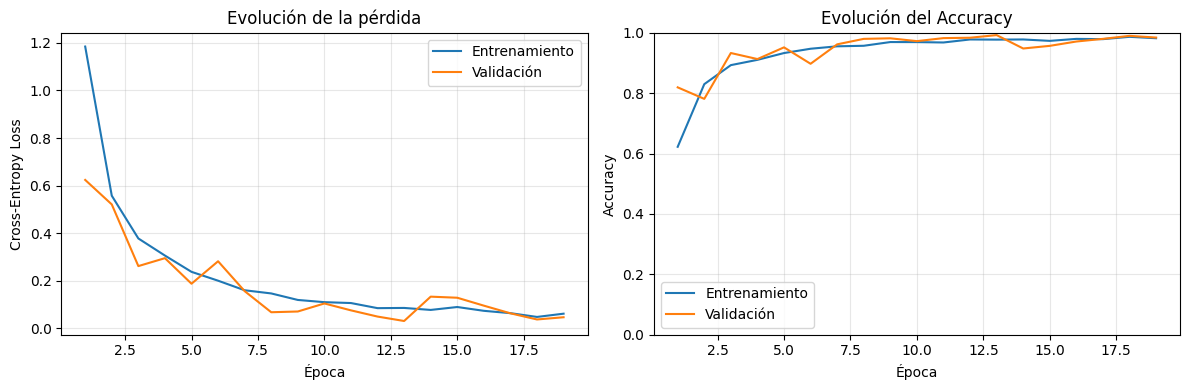


Entrenando experimento: E2_lr
E2_lr | Época 01 | Train Loss: 1.6477 | Train Acc: 0.4906 | Val Loss: 1.0650 | Val Acc: 0.6706
E2_lr | Época 02 | Train Loss: 0.9546 | Train Acc: 0.7176 | Val Loss: 0.6604 | Val Acc: 0.8000
E2_lr | Época 03 | Train Loss: 0.6566 | Train Acc: 0.8266 | Val Loss: 0.4469 | Val Acc: 0.9044
E2_lr | Época 04 | Train Loss: 0.5029 | Train Acc: 0.8668 | Val Loss: 0.3669 | Val Acc: 0.9006
E2_lr | Época 05 | Train Loss: 0.3921 | Train Acc: 0.9011 | Val Loss: 0.2598 | Val Acc: 0.9325
E2_lr | Época 06 | Train Loss: 0.3285 | Train Acc: 0.9150 | Val Loss: 0.2088 | Val Acc: 0.9456
E2_lr | Época 07 | Train Loss: 0.2703 | Train Acc: 0.9293 | Val Loss: 0.1901 | Val Acc: 0.9575
E2_lr | Época 08 | Train Loss: 0.2491 | Train Acc: 0.9357 | Val Loss: 0.1397 | Val Acc: 0.9631
E2_lr | Época 09 | Train Loss: 0.2032 | Train Acc: 0.9505 | Val Loss: 0.1018 | Val Acc: 0.9788
E2_lr | Época 10 | Train Loss: 0.1880 | Train Acc: 0.9546 | Val Loss: 0.1049 | Val Acc: 0.9775
E2_lr | Época 11 | 

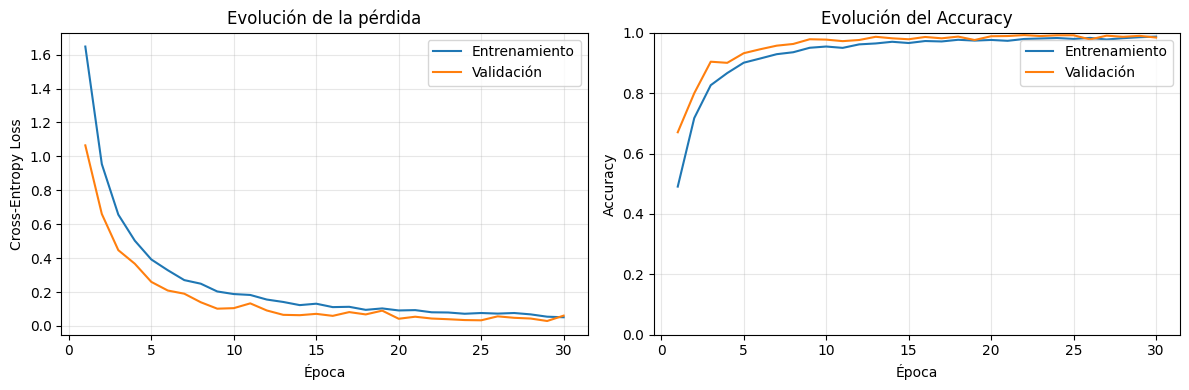


Entrenando experimento: E3_profundidad
E3_profundidad | Época 01 | Train Loss: 0.7789 | Train Acc: 0.7691 | Val Loss: 0.2270 | Val Acc: 0.9456
E3_profundidad | Época 02 | Train Loss: 0.2547 | Train Acc: 0.9264 | Val Loss: 0.1645 | Val Acc: 0.9369
E3_profundidad | Época 03 | Train Loss: 0.1393 | Train Acc: 0.9639 | Val Loss: 0.1519 | Val Acc: 0.9513
E3_profundidad | Época 04 | Train Loss: 0.1292 | Train Acc: 0.9620 | Val Loss: 0.0869 | Val Acc: 0.9794
E3_profundidad | Época 05 | Train Loss: 0.0939 | Train Acc: 0.9720 | Val Loss: 0.0742 | Val Acc: 0.9738
E3_profundidad | Época 06 | Train Loss: 0.0898 | Train Acc: 0.9723 | Val Loss: 0.2497 | Val Acc: 0.9075
E3_profundidad | Época 07 | Train Loss: 0.0652 | Train Acc: 0.9805 | Val Loss: 0.3933 | Val Acc: 0.8862
E3_profundidad | Época 08 | Train Loss: 0.0506 | Train Acc: 0.9846 | Val Loss: 0.0444 | Val Acc: 0.9862
E3_profundidad | Época 09 | Train Loss: 0.0514 | Train Acc: 0.9846 | Val Loss: 0.0320 | Val Acc: 0.9869
E3_profundidad | Época 1

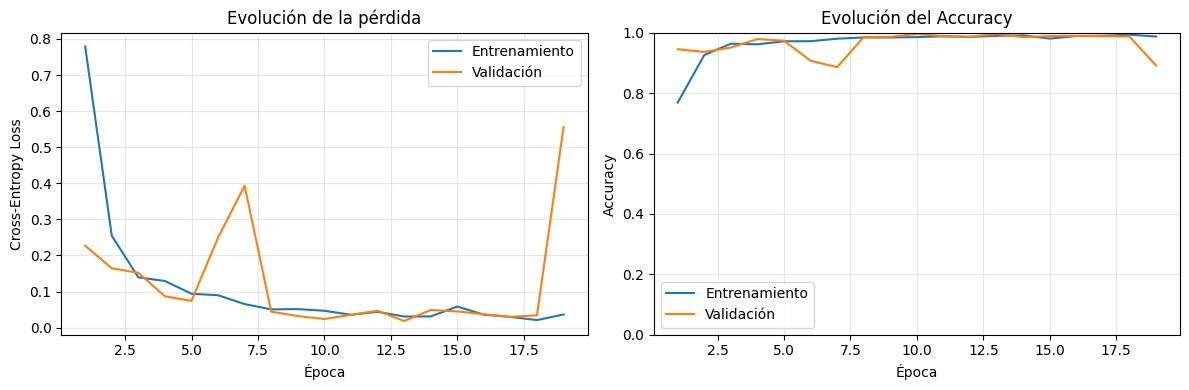


Entrenando experimento: E4_batch_dropout
E4_batch_dropout | Época 01 | Train Loss: 1.2835 | Train Acc: 0.5797 | Val Loss: 0.6761 | Val Acc: 0.7887
E4_batch_dropout | Época 02 | Train Loss: 0.6108 | Train Acc: 0.8137 | Val Loss: 0.4191 | Val Acc: 0.8669
E4_batch_dropout | Época 03 | Train Loss: 0.4018 | Train Acc: 0.8839 | Val Loss: 0.3259 | Val Acc: 0.9031
E4_batch_dropout | Época 04 | Train Loss: 0.3128 | Train Acc: 0.9153 | Val Loss: 0.4495 | Val Acc: 0.8306
E4_batch_dropout | Época 05 | Train Loss: 0.2410 | Train Acc: 0.9362 | Val Loss: 0.1225 | Val Acc: 0.9706
E4_batch_dropout | Época 06 | Train Loss: 0.2071 | Train Acc: 0.9471 | Val Loss: 0.1415 | Val Acc: 0.9644
E4_batch_dropout | Época 07 | Train Loss: 0.1676 | Train Acc: 0.9566 | Val Loss: 0.1137 | Val Acc: 0.9694
E4_batch_dropout | Época 08 | Train Loss: 0.1525 | Train Acc: 0.9600 | Val Loss: 0.0918 | Val Acc: 0.9731
E4_batch_dropout | Época 09 | Train Loss: 0.1384 | Train Acc: 0.9659 | Val Loss: 0.1553 | Val Acc: 0.9469
E4_b

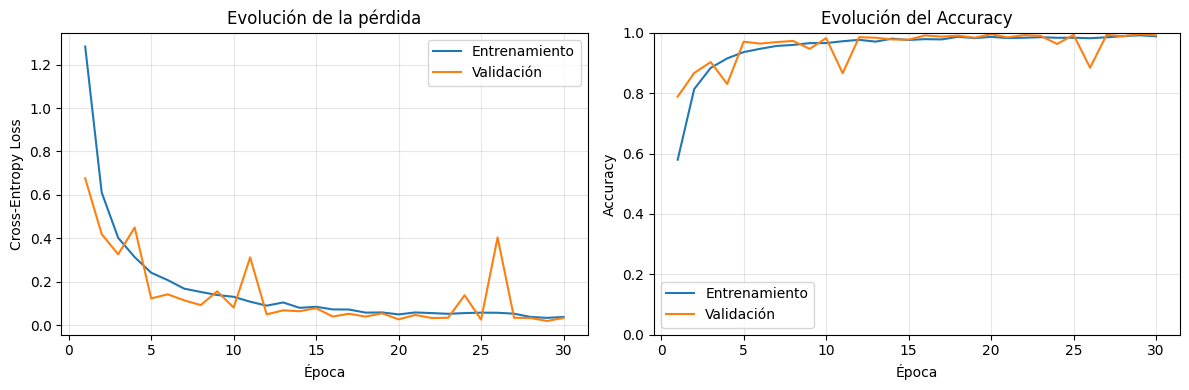


Entrenando experimento: E5_aumento
E5_aumento | Época 01 | Train Loss: 1.2457 | Train Acc: 0.6012 | Val Loss: 0.6876 | Val Acc: 0.7800
E5_aumento | Época 02 | Train Loss: 0.7092 | Train Acc: 0.7707 | Val Loss: 0.4374 | Val Acc: 0.8694
E5_aumento | Época 03 | Train Loss: 0.5474 | Train Acc: 0.8257 | Val Loss: 0.3692 | Val Acc: 0.8544
E5_aumento | Época 04 | Train Loss: 0.4612 | Train Acc: 0.8555 | Val Loss: 0.2579 | Val Acc: 0.9269
E5_aumento | Época 05 | Train Loss: 0.3920 | Train Acc: 0.8766 | Val Loss: 0.1949 | Val Acc: 0.9487
E5_aumento | Época 06 | Train Loss: 0.3415 | Train Acc: 0.8932 | Val Loss: 0.1856 | Val Acc: 0.9519
E5_aumento | Época 07 | Train Loss: 0.3006 | Train Acc: 0.9103 | Val Loss: 0.1498 | Val Acc: 0.9625
E5_aumento | Época 08 | Train Loss: 0.2868 | Train Acc: 0.9123 | Val Loss: 0.1589 | Val Acc: 0.9637
E5_aumento | Época 09 | Train Loss: 0.2325 | Train Acc: 0.9305 | Val Loss: 0.1492 | Val Acc: 0.9556
E5_aumento | Época 10 | Train Loss: 0.2169 | Train Acc: 0.9337 |

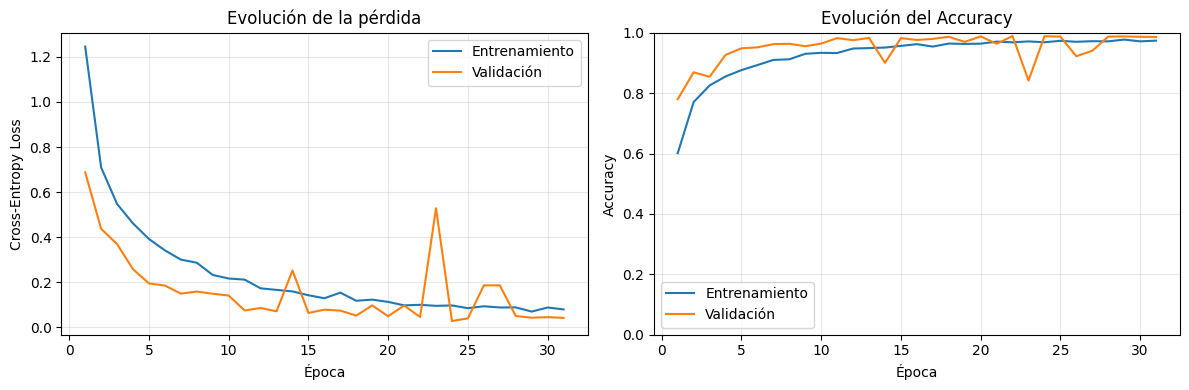


COMPARACIÓN FINAL DE EXPERIMENTOS
            name  best_epoch  best_val_loss  best_val_acc  seconds
  E3_profundidad          13       0.018380      0.996250  4517.81
E4_batch_dropout          29       0.018486      0.995625  3716.10
      E5_aumento          24       0.028360      0.988750  7194.07
           E2_lr          29       0.029115      0.990000  3356.55
         E1_base          13       0.031261      0.992500  2171.50


In [10]:
summaries = []

for cfg in EXPERIMENTS:

    name = cfg['name']

    history_path = RESULTS / f'{name}_history.csv'
    model_path = MODELS / f'{name}.pt'

    if history_path.exists() and model_path.exists():

        print(f'\nRecuperando experimento: {name}')

        history = pd.read_csv(history_path)

        checkpoint = torch.load(
            model_path,
            map_location='cpu',
            weights_only=False
        )

        best_epoch = checkpoint['best_epoch']
        best_row = history.loc[history['epoch'] == best_epoch].iloc[0]

        summary = {
            'name': name,
            'best_epoch': best_epoch,
            'best_val_loss': float(best_row['val_loss']),
            'best_val_acc': float(best_row['val_acc']),
            'seconds': float('nan')
        }

    else:

        print(f'\nEntrenando experimento: {name}')

        summary, history = train_experiment(cfg)

    summaries.append(summary)

    plot_history(history, name)

    summary_df = pd.DataFrame(summaries).sort_values(
        ['best_val_loss', 'best_val_acc'],
        ascending=[True, False]
    )

    summary_df.to_csv(
        RESULTS / 'comparacion_experimentos.csv',
        index=False
    )

print('\nCOMPARACIÓN FINAL DE EXPERIMENTOS')
print(summary_df.to_string(index=False))

## 7. Selección por validación y evaluación final de test

Comparamos los resultados de los cinco experimentos y seleccionamos E3_profundidad porque obtuvo la menor pérdida de validación. Después lo evaluamos con las imágenes de test, consiguiendo un accuracy del 98,75 %. También generamos la matriz de confusión para ver qué categorías se clasificaron correctamente y dónde se produjeron los errores.

Modelo seleccionado: E3_profundidad
Test Accuracy: 0.9914 (99.14%)
Test Macro F1: 0.9918
Imágenes evaluadas: 1509

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

       Apple       0.99      1.00      0.99       204
     Avocado       1.00      1.00      1.00       118
      Banana       1.00      1.00      1.00       112
  Blackberry       1.00      1.00      1.00        85
    Cucumber       1.00      1.00      1.00       249
      Orange       0.99      0.99      0.99       150
        Pear       0.97      0.99      0.98       165
      Pepper       1.00      0.95      0.97       171
  Strawberry       1.00      1.00      1.00       124
      Tomato       0.96      0.99      0.98       131

    accuracy                           0.99      1509
   macro avg       0.99      0.99      0.99      1509
weighted avg       0.99      0.99      0.99      1509



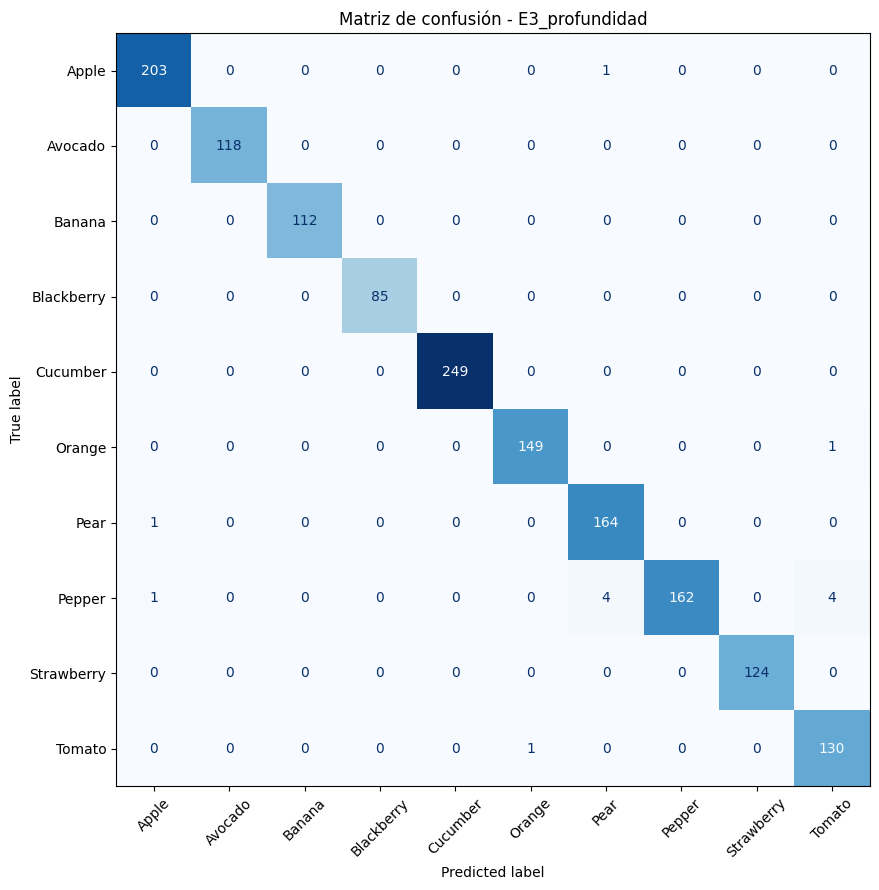

142

In [9]:
summary_df = pd.read_csv(
    RESULTS / 'comparacion_experimentos.csv'
)

summary_df = summary_df.sort_values(
    ['best_val_loss', 'best_val_acc'],
    ascending=[True, False]
)

best_name = summary_df.iloc[0]['name']

checkpoint = torch.load(
    MODELS / f'{best_name}.pt',
    map_location=device,
    weights_only=False
)

cfg = checkpoint['config']

model = ConvNet(
    num_classes=len(checkpoint['classes']),
    filters=tuple(cfg['filters']),
    hidden=cfg['hidden'],
    dropout=cfg['dropout'],
    activation=cfg['activation']
).to(device)

model.load_state_dict(checkpoint['state_dict'])
model.eval()

_, _, test_loader, names = make_loaders(
    cfg['batch'],
    False
)

assert names == checkpoint['classes']

y_true = []
y_pred = []

with torch.no_grad():

    for x, y in test_loader:

        x = x.to(device)

        logits = model(x)
        pred = logits.argmax(dim=1).cpu().numpy()

        y_true.extend(y.numpy())
        y_pred.extend(pred)

acc = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average='macro',
    zero_division=0
)

print('Modelo seleccionado:', best_name)
print(f'Test Accuracy: {acc:.4f} ({acc*100:.2f}%)')
print(f'Test Macro F1: {macro_f1:.4f}')
print('Imágenes evaluadas:', len(y_true))

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(names))),
    target_names=names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).T.to_csv(
    RESULTS / 'test_classification_report.csv'
)

print('\nREPORTE DE CLASIFICACIÓN')

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(names))),
        target_names=names,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(names)))
)

pd.DataFrame(
    cm,
    index=names,
    columns=names
).to_csv(
    RESULTS / 'test_confusion_matrix.csv'
)

fig, ax = plt.subplots(figsize=(10, 9))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=names
).plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45,
    colorbar=False
)

ax.set_title(f'Matriz de confusión - {best_name}')

fig.tight_layout()

fig.savefig(
    FIGURES / 'matriz_confusion_test.png',
    dpi=180
)

plt.show()
plt.close(fig)

(RESULTS / 'test_metrics.json').write_text(
    json.dumps({
        'selected_model': best_name,
        'test_accuracy': acc,
        'test_macro_f1': macro_f1,
        'test_samples': len(y_true)
    }, indent=2)
)

## 8. Extensión opcional: transferencia de aprendizaje con ResNet18

Como ampliación, probamos ResNet18, una red preentrenada en ImageNet. Aprovechamos las características que ya ha aprendido y entrenamos únicamente la última capa para adaptarla a nuestras diez categorías. Conseguimos una pérdida de validación de 0,00454 y un accuracy del 99,93 %, mejorando los resultados de validación de nuestras CNN.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 153MB/s]


ResNet18 | Época 01 | Train Loss: 0.4419 | Train Acc: 0.9107 | Val Loss: 0.1083 | Val Acc: 0.9934 | Tiempo: 61.8s
ResNet18 | Época 02 | Train Loss: 0.0771 | Train Acc: 0.9918 | Val Loss: 0.0635 | Val Acc: 0.9924 | Tiempo: 62.4s
ResNet18 | Época 03 | Train Loss: 0.0452 | Train Acc: 0.9944 | Val Loss: 0.0391 | Val Acc: 0.9958 | Tiempo: 61.5s
ResNet18 | Época 04 | Train Loss: 0.0320 | Train Acc: 0.9956 | Val Loss: 0.0298 | Val Acc: 0.9969 | Tiempo: 62.1s
ResNet18 | Época 05 | Train Loss: 0.0227 | Train Acc: 0.9978 | Val Loss: 0.0227 | Val Acc: 0.9972 | Tiempo: 60.1s
ResNet18 | Época 06 | Train Loss: 0.0177 | Train Acc: 0.9985 | Val Loss: 0.0173 | Val Acc: 0.9976 | Tiempo: 61.5s
ResNet18 | Época 07 | Train Loss: 0.0152 | Train Acc: 0.9986 | Val Loss: 0.0147 | Val Acc: 0.9990 | Tiempo: 59.9s
ResNet18 | Época 08 | Train Loss: 0.0123 | Train Acc: 0.9990 | Val Loss: 0.0106 | Val Acc: 1.0000 | Tiempo: 59.2s
ResNet18 | Época 09 | Train Loss: 0.0104 | Train Acc: 0.9990 | Val Loss: 0.0100 | Val Ac

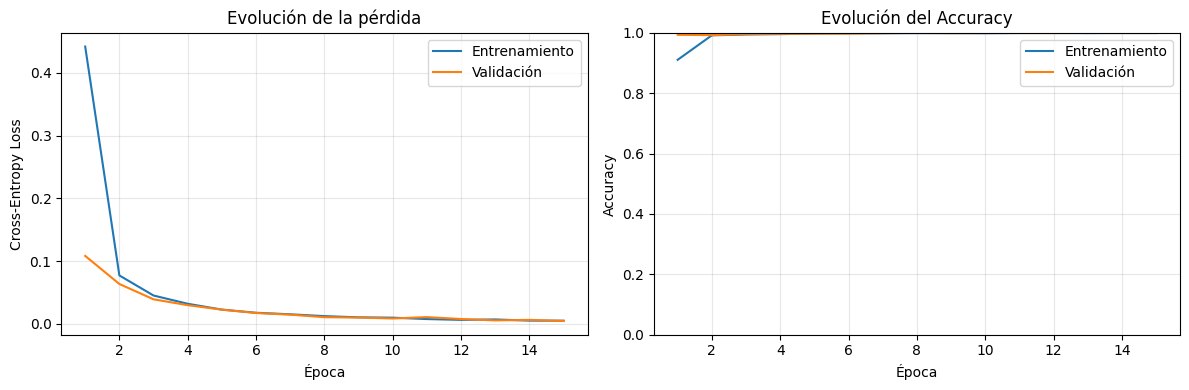


ENTRENAMIENTO RESNET18 FINALIZADO
Mejor época: 15
Mejor pérdida de validación: 0.004542474214561206
Tiempo total: 15.16 minutos


In [14]:
RUN_TRANSFER = True

if RUN_TRANSFER:
    imagenet_weights = models.ResNet18_Weights.DEFAULT

    tf_train = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(8),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])

    tf_eval = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])

    train_t = DataLoader(
        ImageFolder(DATA / 'train', transform=tf_train),
        batch_size=32,
        shuffle=True,
        num_workers=2,
        pin_memory=(device.type == 'cuda')
    )

    val_t = DataLoader(
        ImageFolder(DATA / 'val', transform=tf_eval),
        batch_size=32,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == 'cuda')
    )

    transfer = models.resnet18(weights=imagenet_weights)

    for param in transfer.parameters():
        param.requires_grad = False

    transfer.fc = nn.Linear(
        transfer.fc.in_features,
        len(classes)
    )

    transfer = transfer.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        transfer.fc.parameters(),
        lr=0.001
    )

    best = float('inf')
    wait = 0
    best_state = None
    best_epoch = 0
    rows = []

    start_time = time.time()

    for epoch in range(1, 16):
        epoch_start = time.time()

        transfer.train()

        for module in transfer.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_t:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = transfer(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)

            train_loss += loss.item() * batch_size
            train_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            train_total += batch_size

        tl = train_loss / train_total
        ta = train_correct / train_total

        vl, va = run_epoch(
            transfer,
            val_t,
            criterion
        )

        rows.append({
            'epoch': epoch,
            'train_loss': tl,
            'train_acc': ta,
            'val_loss': vl,
            'val_acc': va
        })

        elapsed = time.time() - epoch_start

        print(
            f'ResNet18 | Época {epoch:02d} | '
            f'Train Loss: {tl:.4f} | '
            f'Train Acc: {ta:.4f} | '
            f'Val Loss: {vl:.4f} | '
            f'Val Acc: {va:.4f} | '
            f'Tiempo: {elapsed:.1f}s',
            flush=True
        )

        if vl < best - 0.0001:
            best = vl
            best_epoch = epoch
            best_state = copy.deepcopy(
                transfer.state_dict()
            )
            wait = 0
        else:
            wait += 1

            if wait >= 4:
                print('Early Stopping activado.')
                break

    transfer.load_state_dict(best_state)
    transfer.eval()

    torch.save(
        {
            'state_dict': best_state,
            'classes': classes,
            'best_epoch': best_epoch,
            'best_val_loss': best
        },
        MODELS / 'resnet18_transfer.pt'
    )

    history = pd.DataFrame(rows)

    history.to_csv(
        RESULTS / 'resnet18_history.csv',
        index=False
    )

    plot_history(
        history,
        'resnet18_transfer'
    )

    total_time = time.time() - start_time

    print('\nENTRENAMIENTO RESNET18 FINALIZADO')
    print('Mejor época:', best_epoch)
    print('Mejor pérdida de validación:', best)
    print('Tiempo total:', round(total_time / 60, 2), 'minutos')

## 9. Búsqueda automática de hiperparámetros — Random Search

Por último, implementamos Random Search para probar automáticamente ocho combinaciones de hiperparámetros. Comparamos sus resultados y encontramos que RS_08 fue la mejor configuración, con una pérdida de validación de 0,01629 y un accuracy del 99,65 %. Esto nos permitió mejorar ligeramente el mejor resultado de la búsqueda manual.


In [10]:
import itertools

SEARCH_SEED = 123
N_RANDOM_TRIALS = 8
SEARCH_EPOCHS = 12
SEARCH_PATIENCE = 4

SEARCH_RESULTS = RESULTS / 'random_search_results.csv'

search_space = {
    'filters': [
        (16, 32, 64),
        (32, 64, 128),
        (32, 64, 128, 128)
    ],
    'hidden': [64, 128, 256],
    'dropout': [0.2, 0.3, 0.4, 0.5],
    'activation': ['relu', 'leaky_relu'],
    'lr': [0.0001, 0.0003, 0.0005, 0.001],
    'batch': [32, 64],
    'augmentation': [False, True]
}

rng = random.Random(SEARCH_SEED)

keys = list(search_space.keys())

combinations = list(
    itertools.product(
        *(search_space[key] for key in keys)
    )
)

selected_combinations = rng.sample(
    combinations,
    k=min(N_RANDOM_TRIALS, len(combinations))
)

random_configs = []

for i, combination in enumerate(selected_combinations, start=1):

    params = dict(zip(keys, combination))

    cfg = {
        'name': f'RS_{i:02d}',
        'filters': list(params['filters']),
        'hidden': params['hidden'],
        'dropout': params['dropout'],
        'activation': params['activation'],
        'lr': params['lr'],
        'batch': params['batch'],
        'epochs': SEARCH_EPOCHS,
        'patience': SEARCH_PATIENCE,
        'augmentation': params['augmentation']
    }

    random_configs.append(cfg)

print('Combinaciones posibles:', len(combinations))
print('Configuraciones seleccionadas:', len(random_configs))

display(pd.DataFrame(random_configs))

Combinaciones posibles: 1152
Configuraciones seleccionadas: 8


,name,filters,hidden,dropout,activation,lr,batch,epochs,patience,augmentation
0,RS_01,"[16, 32, 64]",64,0.5,relu,0.0005,64,12,4,True
1,RS_02,"[32, 64, 128]",128,0.3,relu,0.0003,32,12,4,False
2,RS_03,"[16, 32, 64]",128,0.3,leaky_relu,0.0001,64,12,4,False
3,RS_04,"[32, 64, 128, 128]",64,0.4,relu,0.0001,64,12,4,False
4,RS_05,"[32, 64, 128]",128,0.3,relu,0.0001,32,12,4,True
5,RS_06,"[16, 32, 64]",128,0.4,leaky_relu,0.0010,32,12,4,False
6,RS_07,"[16, 32, 64]",64,0.4,relu,0.0010,64,12,4,False
7,RS_08,"[32, 64, 128, 128]",64,0.2,relu,0.0005,32,12,4,False



RANDOM SEARCH 1/8: RS_01
Experimento recuperado desde Google Drive.
Val Loss: 0.232462 | Val Accuracy: 0.9369

RANDOM SEARCH 2/8: RS_02
Experimento recuperado desde Google Drive.
Val Loss: 0.051985 | Val Accuracy: 0.9881

RANDOM SEARCH 3/8: RS_03
Experimento recuperado desde Google Drive.
Val Loss: 0.399861 | Val Accuracy: 0.9025

RANDOM SEARCH 4/8: RS_04
RS_04 | Época 01 | Train Loss: 1.6936 | Train Acc: 0.5538 | Val Loss: 1.2701 | Val Acc: 0.8100
RS_04 | Época 02 | Train Loss: 1.0835 | Train Acc: 0.7821 | Val Loss: 0.7373 | Val Acc: 0.8872
RS_04 | Época 03 | Train Loss: 0.7084 | Train Acc: 0.8781 | Val Loss: 0.4216 | Val Acc: 0.9533
RS_04 | Época 04 | Train Loss: 0.5008 | Train Acc: 0.9207 | Val Loss: 0.3038 | Val Acc: 0.9616
RS_04 | Época 05 | Train Loss: 0.3696 | Train Acc: 0.9425 | Val Loss: 0.2098 | Val Acc: 0.9654
RS_04 | Época 06 | Train Loss: 0.2826 | Train Acc: 0.9581 | Val Loss: 0.1421 | Val Acc: 0.9841
RS_04 | Época 07 | Train Loss: 0.2230 | Train Acc: 0.9671 | Val Loss: 0

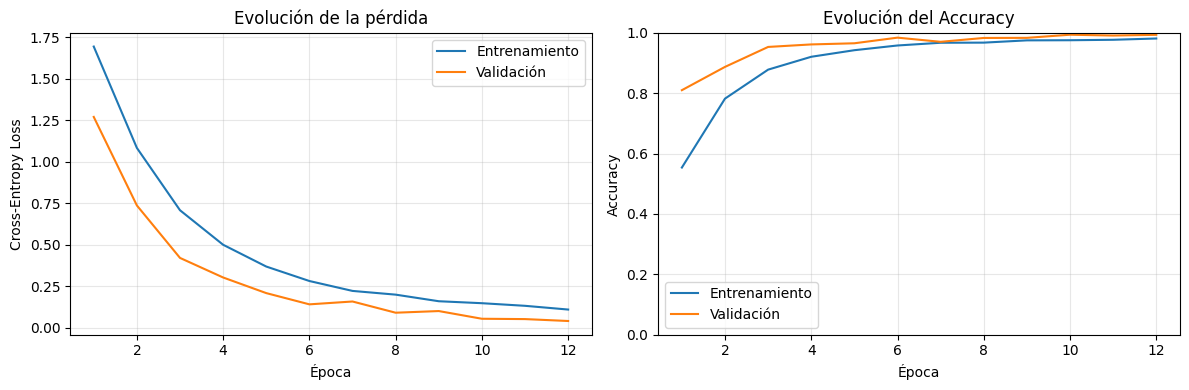

Val Loss: 0.041922 | Val Accuracy: 0.9934

RANDOM SEARCH 5/8: RS_05
RS_05 | Época 01 | Train Loss: 1.6603 | Train Acc: 0.5151 | Val Loss: 1.1896 | Val Acc: 0.6990
RS_05 | Época 02 | Train Loss: 1.0738 | Train Acc: 0.6902 | Val Loss: 0.7796 | Val Acc: 0.8232
RS_05 | Época 03 | Train Loss: 0.8179 | Train Acc: 0.7618 | Val Loss: 0.5771 | Val Acc: 0.8325
RS_05 | Época 04 | Train Loss: 0.6958 | Train Acc: 0.7891 | Val Loss: 0.4666 | Val Acc: 0.8813
RS_05 | Época 05 | Train Loss: 0.5732 | Train Acc: 0.8282 | Val Loss: 0.3828 | Val Acc: 0.9125
RS_05 | Época 06 | Train Loss: 0.5050 | Train Acc: 0.8525 | Val Loss: 0.3437 | Val Acc: 0.9173
RS_05 | Época 07 | Train Loss: 0.4471 | Train Acc: 0.8707 | Val Loss: 0.3208 | Val Acc: 0.9114
RS_05 | Época 08 | Train Loss: 0.4183 | Train Acc: 0.8751 | Val Loss: 0.2400 | Val Acc: 0.9412
RS_05 | Época 09 | Train Loss: 0.3726 | Train Acc: 0.8907 | Val Loss: 0.2597 | Val Acc: 0.9235
RS_05 | Época 10 | Train Loss: 0.3449 | Train Acc: 0.9017 | Val Loss: 0.1997 

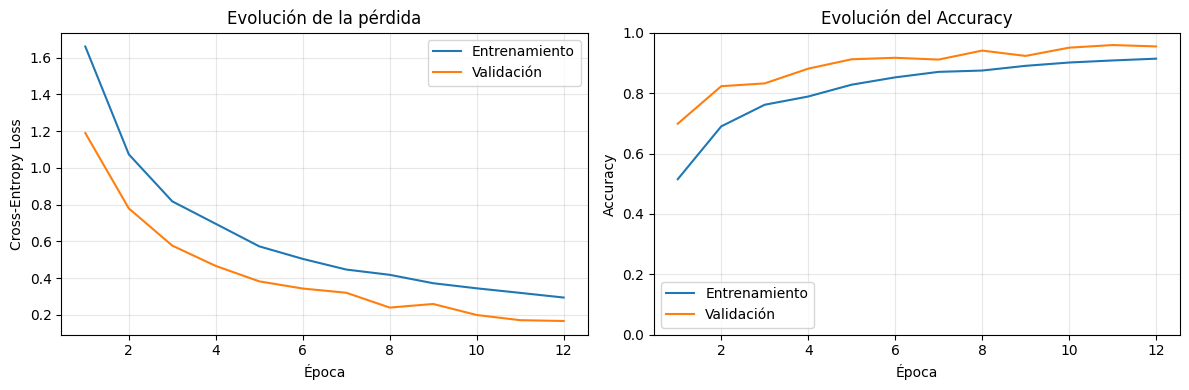

Val Loss: 0.167055 | Val Accuracy: 0.9550

RANDOM SEARCH 6/8: RS_06
RS_06 | Época 01 | Train Loss: 1.0923 | Train Acc: 0.6511 | Val Loss: 0.5254 | Val Acc: 0.8170
RS_06 | Época 02 | Train Loss: 0.5131 | Train Acc: 0.8458 | Val Loss: 0.3338 | Val Acc: 0.8785
RS_06 | Época 03 | Train Loss: 0.3600 | Train Acc: 0.8932 | Val Loss: 0.2109 | Val Acc: 0.9228
RS_06 | Época 04 | Train Loss: 0.3094 | Train Acc: 0.9077 | Val Loss: 0.2794 | Val Acc: 0.9125
RS_06 | Época 05 | Train Loss: 0.2247 | Train Acc: 0.9371 | Val Loss: 0.0898 | Val Acc: 0.9803
RS_06 | Época 06 | Train Loss: 0.1952 | Train Acc: 0.9460 | Val Loss: 0.1970 | Val Acc: 0.9346
RS_06 | Época 07 | Train Loss: 0.1434 | Train Acc: 0.9575 | Val Loss: 0.1850 | Val Acc: 0.9436
RS_06 | Época 08 | Train Loss: 0.1532 | Train Acc: 0.9577 | Val Loss: 0.1229 | Val Acc: 0.9495
RS_06 | Época 09 | Train Loss: 0.1129 | Train Acc: 0.9671 | Val Loss: 0.0606 | Val Acc: 0.9806
RS_06 | Época 10 | Train Loss: 0.1212 | Train Acc: 0.9666 | Val Loss: 0.0868 

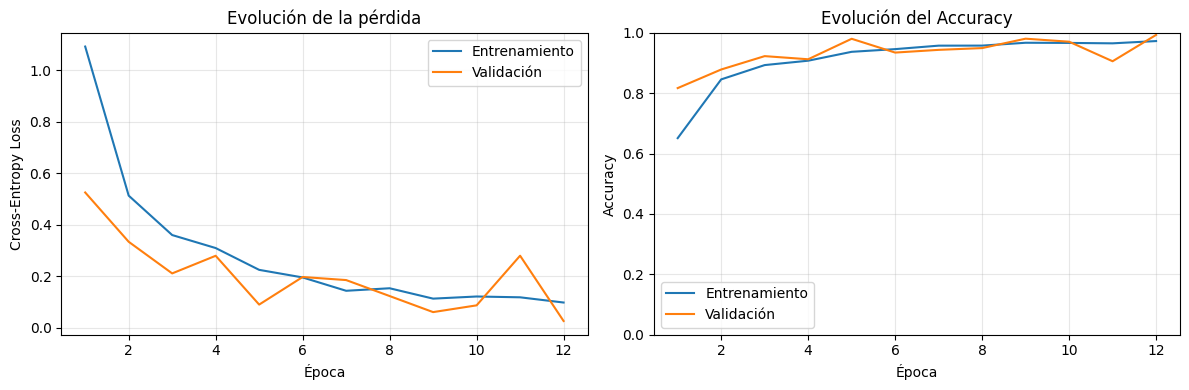

Val Loss: 0.025989 | Val Accuracy: 0.9931

RANDOM SEARCH 7/8: RS_07
RS_07 | Época 01 | Train Loss: 1.4337 | Train Acc: 0.5362 | Val Loss: 0.9154 | Val Acc: 0.7588
RS_07 | Época 02 | Train Loss: 0.7313 | Train Acc: 0.7826 | Val Loss: 0.4154 | Val Acc: 0.8869
RS_07 | Época 03 | Train Loss: 0.5023 | Train Acc: 0.8540 | Val Loss: 0.3657 | Val Acc: 0.8844
RS_07 | Época 04 | Train Loss: 0.4102 | Train Acc: 0.8834 | Val Loss: 0.2899 | Val Acc: 0.9308
RS_07 | Época 05 | Train Loss: 0.3258 | Train Acc: 0.9136 | Val Loss: 0.1973 | Val Acc: 0.9443
RS_07 | Época 06 | Train Loss: 0.2686 | Train Acc: 0.9260 | Val Loss: 0.2514 | Val Acc: 0.9183
RS_07 | Época 07 | Train Loss: 0.2051 | Train Acc: 0.9503 | Val Loss: 0.1824 | Val Acc: 0.9453
RS_07 | Época 08 | Train Loss: 0.2086 | Train Acc: 0.9449 | Val Loss: 0.1040 | Val Acc: 0.9723
RS_07 | Época 09 | Train Loss: 0.1564 | Train Acc: 0.9610 | Val Loss: 0.3283 | Val Acc: 0.8862
RS_07 | Época 10 | Train Loss: 0.2176 | Train Acc: 0.9386 | Val Loss: 0.0894 

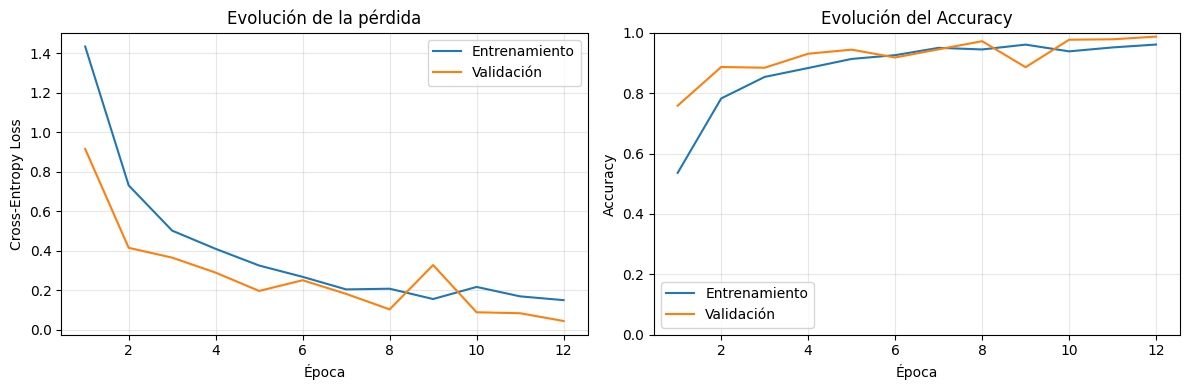

Val Loss: 0.045202 | Val Accuracy: 0.9875

RANDOM SEARCH 8/8: RS_08
RS_08 | Época 01 | Train Loss: 0.8191 | Train Acc: 0.7954 | Val Loss: 0.4151 | Val Acc: 0.8443
RS_08 | Época 02 | Train Loss: 0.2168 | Train Acc: 0.9530 | Val Loss: 0.1613 | Val Acc: 0.9498
RS_08 | Época 03 | Train Loss: 0.1179 | Train Acc: 0.9722 | Val Loss: 0.0575 | Val Acc: 0.9869
RS_08 | Época 04 | Train Loss: 0.0994 | Train Acc: 0.9740 | Val Loss: 0.0745 | Val Acc: 0.9882
RS_08 | Época 05 | Train Loss: 0.0714 | Train Acc: 0.9821 | Val Loss: 0.0268 | Val Acc: 0.9934
RS_08 | Época 06 | Train Loss: 0.0577 | Train Acc: 0.9842 | Val Loss: 0.0749 | Val Acc: 0.9782
RS_08 | Época 07 | Train Loss: 0.0479 | Train Acc: 0.9878 | Val Loss: 0.0225 | Val Acc: 0.9938
RS_08 | Época 08 | Train Loss: 0.0558 | Train Acc: 0.9856 | Val Loss: 0.0185 | Val Acc: 0.9941
RS_08 | Época 09 | Train Loss: 0.0373 | Train Acc: 0.9910 | Val Loss: 0.0529 | Val Acc: 0.9855
RS_08 | Época 10 | Train Loss: 0.0476 | Train Acc: 0.9877 | Val Loss: 0.0278 

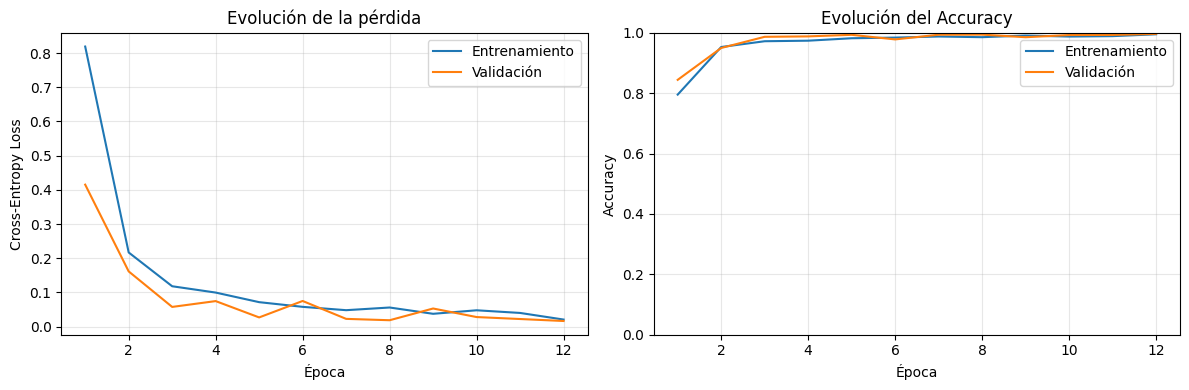

Val Loss: 0.016289 | Val Accuracy: 0.9965

RESULTADOS DE RANDOM SEARCH


,name,filters,hidden,dropout,activation,lr,batch,augmentation,best_epoch,best_val_loss,best_val_acc
0,RS_08,"[32, 64, 128, 128]",64,0.2,relu,0.0005,32,False,12,0.016289,0.996540
1,RS_06,"[16, 32, 64]",128,0.4,leaky_relu,0.0010,32,False,12,0.025989,0.993080
2,RS_04,"[32, 64, 128, 128]",64,0.4,relu,0.0001,64,False,12,0.041922,0.993426
3,RS_07,"[16, 32, 64]",64,0.4,relu,0.0010,64,False,12,0.045202,0.987543
4,RS_02,"[32, 64, 128]",128,0.3,relu,0.0003,32,False,12,0.051985,0.988125
5,RS_05,"[32, 64, 128]",128,0.3,relu,0.0001,32,True,12,0.167055,0.955017
6,RS_01,"[16, 32, 64]",64,0.5,relu,0.0005,64,True,11,0.232462,0.936875
7,RS_03,"[16, 32, 64]",128,0.3,leaky_relu,0.0001,64,False,12,0.399861,0.902500


In [11]:
random_results = []

for i, cfg in enumerate(random_configs, start=1):

    name = cfg['name']

    history_path = RESULTS / f'{name}_history.csv'
    model_path = MODELS / f'{name}.pt'

    print(f'\n{"=" * 60}')
    print(f'RANDOM SEARCH {i}/{len(random_configs)}: {name}')
    print(f'{"=" * 60}')

    if history_path.exists() and model_path.exists():

        history = pd.read_csv(history_path)

        best_idx = history['val_loss'].idxmin()
        best_row = history.loc[best_idx]

        summary = {
            'name': name,
            'best_epoch': int(best_row['epoch']),
            'best_val_loss': float(best_row['val_loss']),
            'best_val_acc': float(best_row['val_acc']),
            'seconds': np.nan
        }

        print('Experimento recuperado desde Google Drive.')

    else:

        summary, history = train_experiment(
            cfg,
            save=True
        )

        plot_history(history, name)

    random_results.append({
        **cfg,
        'best_epoch': summary['best_epoch'],
        'best_val_loss': summary['best_val_loss'],
        'best_val_acc': summary['best_val_acc'],
        'seconds': summary['seconds']
    })

    pd.DataFrame(random_results).to_csv(
        SEARCH_RESULTS,
        index=False
    )

    print(
        f"Val Loss: {summary['best_val_loss']:.6f} | "
        f"Val Accuracy: {summary['best_val_acc']:.4f}"
    )

random_df = pd.DataFrame(random_results)

random_df = random_df.sort_values(
    ['best_val_loss', 'best_val_acc'],
    ascending=[True, False]
).reset_index(drop=True)

random_df.to_csv(
    SEARCH_RESULTS,
    index=False
)

print('\nRESULTADOS DE RANDOM SEARCH')

display(
    random_df[
        [
            'name',
            'filters',
            'hidden',
            'dropout',
            'activation',
            'lr',
            'batch',
            'augmentation',
            'best_epoch',
            'best_val_loss',
            'best_val_acc'
        ]
    ]
)

In [12]:
manual_df = pd.read_csv(
    RESULTS / 'comparacion_experimentos.csv'
)

manual_df = manual_df.sort_values(
    ['best_val_loss', 'best_val_acc'],
    ascending=[True, False]
).reset_index(drop=True)

random_df = pd.read_csv(
    SEARCH_RESULTS
)

random_df = random_df.sort_values(
    ['best_val_loss', 'best_val_acc'],
    ascending=[True, False]
).reset_index(drop=True)

manual_best = manual_df.iloc[0]
random_best = random_df.iloc[0]

comparison = pd.DataFrame([
    {
        'method': 'Manual',
        'model': manual_best['name'],
        'best_val_loss': manual_best['best_val_loss'],
        'best_val_acc': manual_best['best_val_acc']
    },
    {
        'method': 'Random Search',
        'model': random_best['name'],
        'best_val_loss': random_best['best_val_loss'],
        'best_val_acc': random_best['best_val_acc']
    }
])

comparison.to_csv(
    RESULTS / 'comparacion_manual_random_search.csv',
    index=False
)

display(comparison)

print('\nMejor configuración automática:')

for key in [
    'filters',
    'hidden',
    'dropout',
    'activation',
    'lr',
    'batch',
    'augmentation'
]:
    print(f'{key}: {random_best[key]}')

,method,model,best_val_loss,best_val_acc
0,Manual,E3_profundidad,0.018380,0.99625
1,Random Search,RS_08,0.016289,0.99654



Mejor configuración automática:
filters: [32, 64, 128, 128]
hidden: 64
dropout: 0.2
activation: relu
lr: 0.0005
batch: 32
augmentation: False


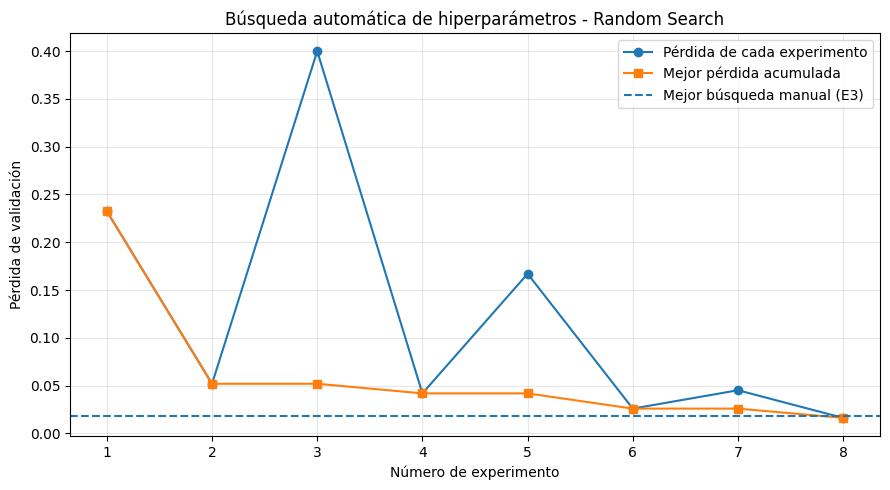

In [13]:
progress_df = pd.read_csv(
    SEARCH_RESULTS
)

progress_df['trial_number'] = (
    progress_df['name'].str.extract(r'RS_(\d+)').astype(int)
)

progress_df = progress_df.sort_values(
    'trial_number'
)

progress_df['best_so_far'] = (
    progress_df['best_val_loss'].cummin()
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    progress_df['trial_number'],
    progress_df['best_val_loss'],
    marker='o',
    label='Pérdida de cada experimento'
)

ax.plot(
    progress_df['trial_number'],
    progress_df['best_so_far'],
    marker='s',
    label='Mejor pérdida acumulada'
)

ax.axhline(
    float(manual_best['best_val_loss']),
    linestyle='--',
    label='Mejor búsqueda manual (E3)'
)

ax.set_title(
    'Búsqueda automática de hiperparámetros - Random Search'
)

ax.set_xlabel('Número de experimento')
ax.set_ylabel('Pérdida de validación')

ax.set_xticks(
    progress_df['trial_number']
)

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURES / 'random_search_progress.png',
    dpi=160
)

plt.show()
plt.close(fig)